In [1]:
# 라이브러리
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import joblib

from google.colab import drive

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)
from sklearn.metrics import accuracy_score

# Google Drive 연결
drive.mount('/content/drive')

# 파일 경로
path = '/content/drive/MyDrive/인공지능/AI_Project1/problem2.data'


Mounted at /content/drive


In [2]:
# 데이터 불러오기
df = pd.read_csv(path)

# 데이터 크기 확인
print("데이터 크기:", df.shape)

# 상위 행 미리보기
print("상위 행 미리보기:")
display(df.head())

# 통계 요약
print("통계 요약:")
display(df.describe())

데이터 크기: (3726, 58)
상위 행 미리보기:


,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,y
0,0.00,0.0,3.38,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.000,0.000,0.0,0.000,1.222,3,11,0
1,0.00,0.0,0.00,0.0,0.0,0.00,0.00,0.00,0.00,0.00,...,0.0,0.000,0.000,0.000,0.0,0.000,1.000,1,5,0
2,2.32,0.0,0.00,0.0,0.0,0.77,0.00,0.00,0.00,0.00,...,0.0,0.000,0.000,0.159,0.0,0.000,1.346,4,35,0
3,0.00,0.0,0.23,0.0,0.0,0.00,0.23,0.00,0.00,0.95,...,0.0,0.123,0.000,0.197,0.0,0.024,5.038,280,519,1
4,0.00,0.0,0.33,0.0,0.0,0.49,0.00,1.32,0.16,5.12,...,0.0,0.070,0.023,0.000,0.0,0.023,1.552,10,149,0


통계 요약:


,0,1,2,3,4,5,6,7,8,9,...,48,49,50,51,52,53,54,55,56,y
count,3726.000000,3726.000000,3726.000000,3726.000000,3726.00000,3726.000000,3726.000000,3726.000000,3726.000000,3726.000000,...,3726.000000,3726.000000,3726.000000,3726.000000,3726.000000,3726.000000,3726.000000,3726.000000,3726.000000,3726.000000
mean,0.103599,0.216836,0.279249,0.064855,0.30978,0.095062,0.111404,0.100931,0.090513,0.242649,...,0.040175,0.140620,0.016582,0.270222,0.077245,0.042313,5.074338,52.463768,286.352657,0.393988
std,0.306780,1.305296,0.501176,1.400595,0.67173,0.275718,0.391650,0.345555,0.275245,0.644687,...,0.250579,0.284194,0.109539,0.859684,0.248816,0.417943,29.343369,204.906105,616.456589,0.488698
min,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.583000,6.000000,35.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.065000,0.000000,0.000000,0.000000,0.000000,2.282000,15.000000,95.000000,0.000000
75%,0.000000,0.000000,0.410000,0.000000,0.38000,0.000000,0.000000,0.000000,0.000000,0.167500,...,0.000000,0.189000,0.000000,0.314750,0.051750,0.000000,3.761000,43.750000,272.000000,1.000000
max,4.540000,14.280000,5.100000,42.810000,10.00000,5.880000,7.270000,6.060000,5.260000,18.180000,...,4.385000,9.752000,4.081000,32.478000,6.003000,19.829000,1021.500000,9989.000000,15841.000000,1.000000


In [3]:
# Feature, Label 분리

# 정답(y열) 삭제
X = df.drop(columns=['y'])

# 정답열
y = df['y']

print("Feature 데이터:", X.shape)
print("Label 데이터:", y.shape)

print("클래스별 데이터 개수:")
print(y.value_counts())

Feature 데이터: (3726, 57)
Label 데이터: (3726,)
클래스별 데이터 개수:
y
0    2258
1    1468
Name: count, dtype: int64


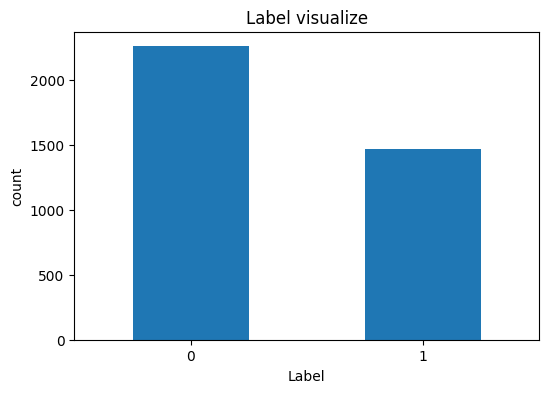

In [4]:
# Label 시각화

# 클래스별 샘플 개수
class_counts = y.value_counts().sort_index()

# 막대그래프로 시각화
class_counts.plot(kind='bar', figsize=(6, 4))

plt.title("Label visualize")
plt.xlabel("Label")
plt.ylabel("count")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.show()

In [5]:
# 학습셋 70%, 검증셋 15%, 테스트셋 15%로 분리

# 전체 데이터 개수
n = len(X)

# 인덱스 랜덤화
np.random.seed(42)
idx = np.random.permutation(n)

# 랜덤화된 인덱스를 데이터에 적용
X = X.iloc[idx].reset_index(drop=True)
y = y.iloc[idx].reset_index(drop=True)

# Train 70%, Validation 15%, Test 15% 분리
train_end = int(n * 0.7)
val_end = int(n * 0.85)

X_train = X[:train_end]
y_train = y[:train_end]

X_val = X[train_end:val_end]
y_val = y[train_end:val_end]

X_test = X[val_end:]
y_test = y[val_end:]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (2608, 57)
Validation: (559, 57)
Test: (559, 57)


In [6]:
# 학습하고 정확도 비교

# STEP 4~5. 기본 분류 모델 학습 및 성능 비교

# 결과와 학습 완료 모델 저장
results = []
all_models = {}

# 1. Decision Tree
model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

# 학습
model.fit(X_train, y_train)

# 검증 데이터 예측
y_pred = model.predict(X_val)

# 정확도 계산
accuracy = accuracy_score(y_val, y_pred)

# 결과 저장
results.append({
    "model": "Decision Tree",
    "validation_accuracy": accuracy
})
all_models["Decision Tree"] = model

print("Decision Tree:", accuracy)

# 2. Random Forest
model = RandomForestClassifier(
    n_estimators=200,
    bootstrap=True,
    min_samples_leaf=2,
    random_state=42
)

# 학습
model.fit(X_train, y_train)

# 검증 데이터 예측
y_pred = model.predict(X_val)

# 정확도 계산
accuracy = accuracy_score(y_val, y_pred)

# 결과 저장
results.append({
    "model": "Random Forest",
    "validation_accuracy": accuracy
})
all_models["Random Forest"] = model

print("Random Forest:", accuracy)

## 3. HistGradientBoosting
model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_leaf_nodes=20,
    l2_regularization=1.0,
    random_state=42
)

# 학습
model.fit(X_train, y_train)

# 검증 데이터 예측
y_pred = model.predict(X_val)

# 정확도 계산
accuracy = accuracy_score(y_val, y_pred)

# 결과 저장
results.append({
    "model": "HistGradientBoosting",
    "validation_accuracy": accuracy
})
all_models["HistGradientBoosting"] = model

print("HistGradientBoosting:", accuracy)

Decision Tree: 0.9105545617173524
Random Forest: 0.9552772808586762
HistGradientBoosting: 0.9570661896243292


In [7]:
# 하이퍼파라미터를 변경해보자

## Decision Tree - depth 변경 (3, 8, 12로)
for depth in [3, 8, 12]:

    model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        random_state=42
    )

    # 학습
    model.fit(X_train, y_train)

    # 검증 데이터 예측
    y_pred = model.predict(X_val)

    # 정확도 계산
    accuracy = accuracy_score(y_val, y_pred)

    # 결과 저장
    name = f"DT_depth{depth}"
    results.append({
        "model": name,
        "validation_accuracy": accuracy
    })
    all_models[name] = model

    print(name, accuracy)

DT_depth3 0.9069767441860465
DT_depth8 0.9141323792486583
DT_depth12 0.9105545617173524


In [8]:
## Decision Tree - criterion 변경 -> Entropy로
model = DecisionTreeClassifier(
    criterion="entropy",
    max_depth=5,
    random_state=42
)

# 학습
model.fit(X_train, y_train)

# 검증 데이터 예측
y_pred = model.predict(X_val)

# 정확도 계산
accuracy = accuracy_score(y_val, y_pred)

# 결과 저장
name = "DT_entropy"
results.append({
    "model": name,
    "validation_accuracy": accuracy
})
all_models[name] = model

print(name, accuracy)

DT_entropy 0.924865831842576


In [9]:
## Decision Tree - 가지치기 강도 변경
for alpha in [0.001, 0.01]:

    model = DecisionTreeClassifier(
        max_depth=5,
        ccp_alpha=alpha,
        random_state=42
    )

    # 학습
    model.fit(X_train, y_train)

    # 검증 데이터 예측
    y_pred = model.predict(X_val)

    # 정확도 계산
    accuracy = accuracy_score(y_val, y_pred)

    # 결과 저장
    name = f"DT_alpha{alpha}"
    results.append({
        "model": name,
        "validation_accuracy": accuracy
    })

    all_models[name] = model

    print(name, accuracy)

DT_alpha0.001 0.9105545617173524
DT_alpha0.01 0.9016100178890877


In [10]:
## Random Forest - 트리 개수 100, 300 설정 (기존200)
for n_trees in [100, 300]:
    model = RandomForestClassifier(
        n_estimators=n_trees,
        bootstrap=True,
        min_samples_leaf=2,
        random_state=42
    )

    name = f"RF_trees{n_trees}"

    # 모델 학습
    model.fit(X_train, y_train)

    # 검증 데이터 예측
    y_pred = model.predict(X_val)

    # 정확도 계산
    accuracy = accuracy_score(y_val, y_pred)

    # 결과 저장
    results.append({
        "model": name,
        "validation_accuracy": accuracy
    })

    all_models[name] = model

    print(name, accuracy)


RF_trees100 0.9534883720930233
RF_trees300 0.9534883720930233


In [11]:
# Random Forest - 복원추출 사용X (bootstrap=False)
model = RandomForestClassifier(
    n_estimators=200,
    bootstrap=False,
    min_samples_leaf=2,
    random_state=42
)

# 모델 학습
model.fit(X_train, y_train)

# 검증 데이터 예측
y_pred = model.predict(X_val)

# 정확도 계산
accuracy = accuracy_score(y_val, y_pred)

# 결과 저장
name = "RF_bootstrapFalse"
results.append({
    "model": name,
    "validation_accuracy": accuracy
})
all_models[name] = model

print(name, accuracy)

RF_bootstrapFalse 0.9534883720930233


In [12]:
# HistGradientBoosting - 하이퍼파라미터 실험

# 반복 횟수, 학습률, 최대 leaf노드수, l2 regularization 정도 변경
experiments = [
    ("HGB_iter100", {"max_iter": 100}),
    ("HGB_iter350", {"max_iter": 350}),
    ("HGB_lr001", {"learning_rate": 0.01}),
    ("HGB_lr01", {"learning_rate": 0.1}),
    ("HGB_leaf10", {"max_leaf_nodes": 10}),
    ("HGB_l2_0", {"l2_regularization": 0.0})
]

# 기본 하이퍼파라미터
base_params = {
    "max_iter": 200,
    "learning_rate": 0.05,
    "max_leaf_nodes": 20,
    "l2_regularization": 1.0,
    "random_state": 42
}

for name, changes in experiments:

    # 기존 파라미터는 복사
    params = base_params.copy()
    params.update(changes)

    # 모델 생성
    model = HistGradientBoostingClassifier(**params)

    # 학습
    model.fit(X_train, y_train)

    # 검증 데이터 예측
    y_pred = model.predict(X_val)

    # 정확도 계산
    accuracy = accuracy_score(y_val, y_pred)

    # 결과 저장
    results.append({
        "model": name,
        "validation_accuracy": accuracy
    })

    all_models[name] = model

    print(name, accuracy)


HGB_iter100 0.9499105545617174
HGB_iter350 0.9552772808586762
HGB_lr001 0.9445438282647585
HGB_lr01 0.9534883720930233
HGB_leaf10 0.9516994633273703
HGB_l2_0 0.9570661896243292


In [13]:
# 분류 model 결과 비교

# 정확도 내림차순 정렬 (정확도가 같을 때는 실험 순서 유지)
results_df = pd.DataFrame(results).sort_values(
    by="validation_accuracy",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

# 전체 결과 확인
display(results_df)

# 가장 높은 정확도 구하기
best_accuracy = results_df["validation_accuracy"].max()

# 가장 높은 정확도가 중복되는 모델 저장
tied_models = results_df[
    results_df["validation_accuracy"] == best_accuracy
]["model"].tolist()
print("공동 1등:", tied_models)

# 정확도가 같으면 먼저 실험한 모델을 선택
best_name = results_df.iloc[0]["model"]

# 최종 모델
model = all_models[best_name]


,model,validation_accuracy
0,HistGradientBoosting,0.957066
1,HGB_l2_0,0.957066
2,Random Forest,0.955277
3,HGB_iter350,0.955277
4,RF_trees100,0.953488
5,RF_trees300,0.953488
6,RF_bootstrapFalse,0.953488
7,HGB_lr01,0.953488
8,HGB_leaf10,0.951699
9,HGB_iter100,0.949911


공동 1등: ['HistGradientBoosting', 'HGB_l2_0']


In [14]:
# 가장 높은 검증 정확도를 기록한 모델 저장
model = all_models[best_name]
model_path = os.path.join(
    os.path.dirname(path),
    "problem2_홍영규_202302125.pkl"
)
joblib.dump(model, model_path)
print("선택된 모델:", best_name)
print("모델 저장 경로:", model_path)

선택된 모델: HistGradientBoosting
모델 저장 경로: /content/drive/MyDrive/인공지능/AI_Project1/problem2_홍영규_202302125.pkl


In [19]:
# 저장한 모델이 정상적으로 불러와지는지 확인
model = joblib.load(model_path)

print("모델 로드:", type(model).__name__)

# 최종 모델의 테스트 정확도 확인
test_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_pred)

print("테스트 정확도:", test_accuracy)

모델 로드: HistGradientBoostingClassifier
테스트 정확도: 0.9427549194991055
